# Greenpod Labs - Data Science Assignment 2
## Computer Vision Pipeline for Citrus Quality & Disease Classification
**Author / Candidate:** Data Science Candidate  
**Objective:** End-to-end computer vision workflow comparing Classical Feature Extraction + Machine Learning (Approach 1) vs. Lightweight Deep Learning Transfer Learning (Approach 2) on real-world post-harvest citrus produce.

In [19]:
import os
import zipfile
import gdown

# Standalone Public Download
if not os.path.exists("data/train"):
    print("Downloading dataset from public archive...")
    gdown.download(id="1NMJ0FOxcWH1mwFFeERuY6fgEY-MVgeET", output="Orange_Dataset.zip", quiet=False)

    print("Extracting dataset archive...")
    with zipfile.ZipFile("Orange_Dataset.zip", 'r') as zip_ref:
        zip_ref.extractall("data")
    print("Dataset successfully extracted! Classes:", os.listdir("data/train"))
else:
    print("Dataset already present in runtime.")

Dataset already present in runtime.


## 1. Dataset Acquisition & Extraction
- Mounting Google Drive storage.
- Extracting the raw dataset archive (`data/train` and `data/test`).
- Verifying the underlying class folder hierarchy (`fresh`, `grenning`, `blackspot`, `canker`).

In [13]:
import os
import zipfile
import shutil

# Step 1: Check dataset location (Google Drive or Direct Download)
drive_zip = "/content/drive/MyDrive/Orange Dataset.zip"
local_zip = "Orange_Dataset.zip"

if os.path.exists(drive_zip):
    print("Found dataset archive in Google Drive. Extracting...")
    with zipfile.ZipFile(drive_zip, 'r') as zip_ref:
        zip_ref.extractall("data")
    print("Extraction successfully completed from Google Drive.")
else:
    print("Dataset archive not found in Drive. Initiating direct download...")
    import gdown
    gdown.download(id="1NMJ0FOxcWH1mwFFeERuY6fgEY-MVgeET", output=local_zip, quiet=False)
    if os.path.exists(local_zip):
        with zipfile.ZipFile(local_zip, 'r') as zip_ref:
            zip_ref.extractall("data")
        print("Extraction successfully completed from direct download.")

# Step 2: Verify extracted directory structure
print("\nExtracted directory contents in 'data':")
if os.path.exists("data"):
    print(os.listdir("data"))

Found dataset archive in Google Drive. Extracting...
Extraction successfully completed from Google Drive.

Extracted directory contents in 'data':
['test', 'train']


## 2. Exploratory Data Analysis (EDA) & Dataset Health Audit
- Quantifying sample counts across Train and Test partitions.
- Identifying class imbalances (e.g., high sample count in `grenning` vs. `canker`/`blackspot`).
- Detecting resolution and camera sensor biases across classes.

=== Dataset Distribution Summary ===
Split Class_Name  Image_Count Sample_Resolution
Train  blackspot          184           800x800
Train     canker          179           800x800
Train      fresh          281           362x386
Train   grenning          347           800x800
 Test  blackspot           22           800x800
 Test     canker           22           800x800
 Test      fresh           33           306x288
 Test   grenning           22           800x800

Total Dataset Images: 1090


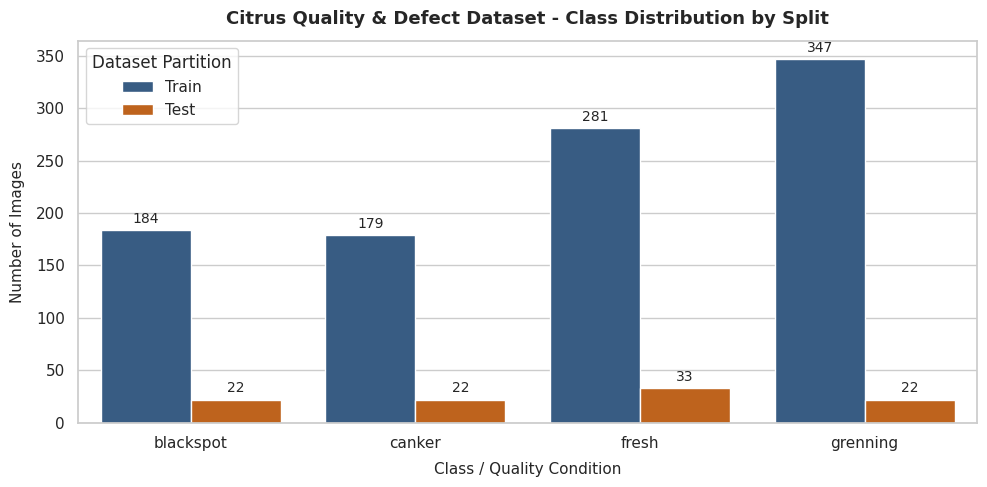

In [14]:
import os
import glob
from typing import Dict, List, Tuple
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Set visualization style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

def audit_dataset_distribution(base_dir: str = "data") -> pd.DataFrame:
    """
    Audits image counts, verifies class balance, and checks image resolutions
    across train and test splits.
    """
    records = []
    splits = [d for d in ["train", "test"] if os.path.exists(os.path.join(base_dir, d))]

    for split in splits:
        split_path = os.path.join(base_dir, split)
        classes = sorted([c for c in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, c))])

        for class_name in classes:
            class_folder = os.path.join(split_path, class_name)
            image_files = glob.glob(os.path.join(class_folder, "*.*"))
            # Filter valid image extensions
            image_files = [f for f in image_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

            # Inspect sample image dimensions
            resolutions = []
            for img_path in image_files[:10]:  # Sample first 10 for dimension audit
                try:
                    with Image.open(img_path) as img:
                        resolutions.append(img.size)  # (width, height)
                except Exception:
                    continue

            sample_res = f"{resolutions[0][0]}x{resolutions[0][1]}" if resolutions else "N/A"
            records.append({
                "Split": split.capitalize(),
                "Class_Name": class_name,
                "Image_Count": len(image_files),
                "Sample_Resolution": sample_res
            })

    df = pd.DataFrame(records)
    return df

# Execute audit
df_dist = audit_dataset_distribution("data")
print("=== Dataset Distribution Summary ===")
print(df_dist.to_string(index=False))

# Calculate total images and class imbalance ratio
total_images = df_dist["Image_Count"].sum()
print(f"\nTotal Dataset Images: {total_images}")

# Visualization: Class Distribution Bar Chart
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_dist, x="Class_Name", y="Image_Count", hue="Split", palette=["#2b5c8f", "#d95f02"])
plt.title("Citrus Quality & Defect Dataset - Class Distribution by Split", fontsize=13, weight="bold", pad=12)
plt.xlabel("Class / Quality Condition", fontsize=11, labelpad=8)
plt.ylabel("Number of Images", fontsize=11, labelpad=8)
plt.legend(title="Dataset Partition")

# Annotate counts on top of bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{int(height)}",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

## 3. Visualizing Feature Descriptors: Color Spaces (CIELAB) & Micro-Texture (LBP)
- **CIELAB $a^*$ & $b^*$ Channels:** Captures color transitions (green-yellow chlorosis vs. necrotic dark spots).
- **Local Binary Patterns (LBP):** Quantifies micro-surface roughness and lesions on citrus peels.

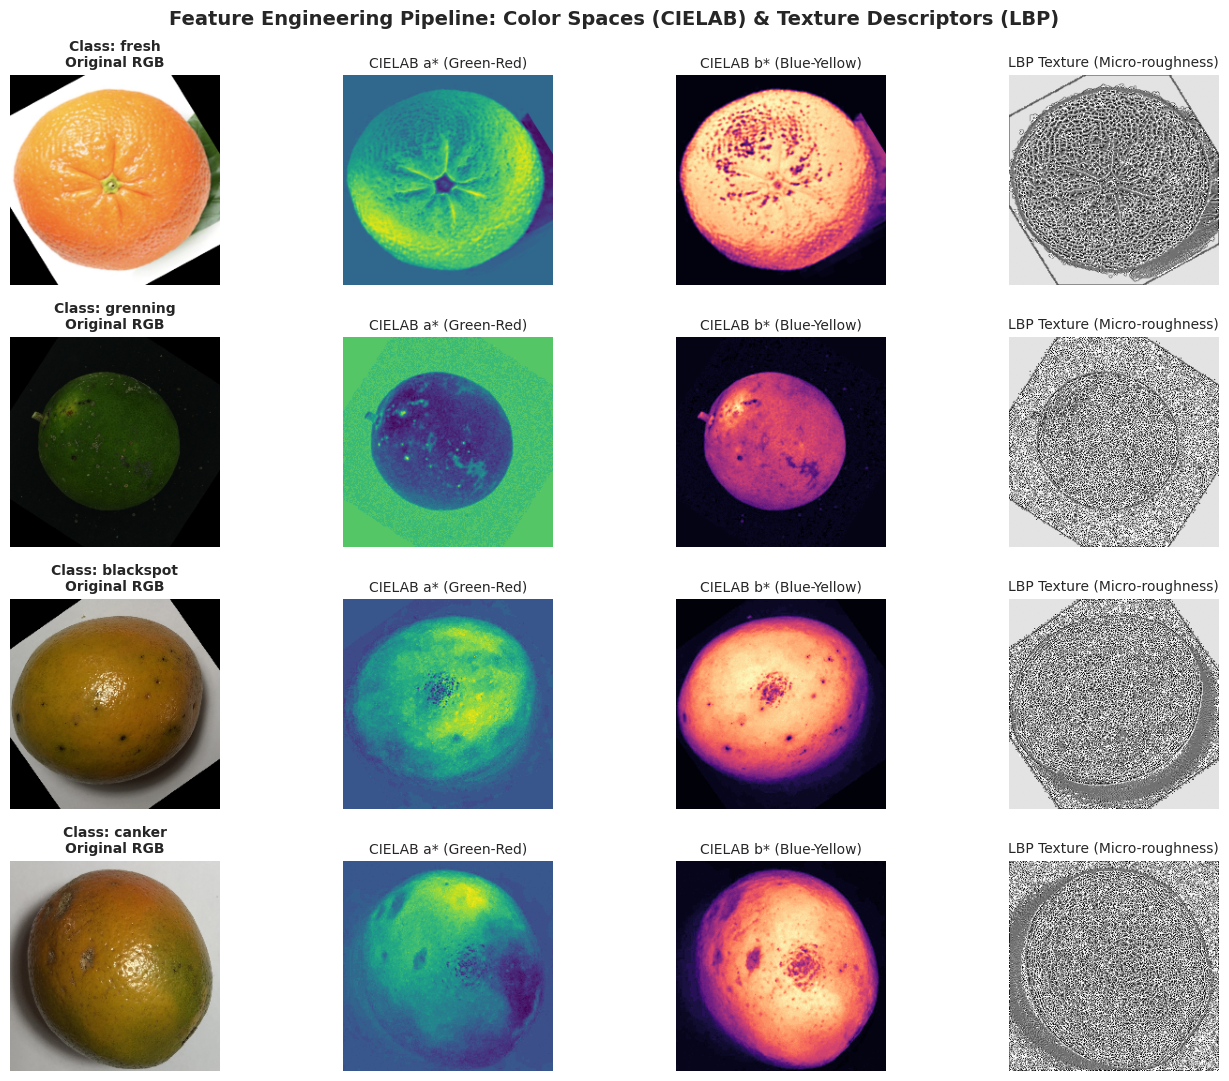

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

def visualize_feature_extraction_pipeline(base_dir: str = "data/train"):
    """
    Visualizes RGB, CIELAB (L*, a*, b*), and Local Binary Pattern (LBP)
    texture descriptors across all 4 citrus conditions.
    """
    classes = ["fresh", "grenning", "blackspot", "canker"]
    fig, axes = plt.subplots(len(classes), 4, figsize=(14, 11))

    # LBP Parameters: P=8 sampling points, R=1 radius
    lbp_radius = 1
    lbp_points = 8 * lbp_radius

    for row_idx, cls_name in enumerate(classes):
        cls_dir = os.path.join(base_dir, cls_name)
        img_files = [f for f in os.listdir(cls_dir) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
        if not img_files:
            continue

        sample_path = os.path.join(cls_dir, img_files[0])
        img_bgr = cv2.imread(sample_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, (224, 224))

        # 1. CIELAB Color Space Transformation
        lab = cv2.cvtColor(cv2.resize(img_bgr, (224, 224)), cv2.COLOR_BGR2LAB)
        l_channel, a_channel, b_channel = cv2.split(lab)

        # 2. Local Binary Pattern (LBP) Texture Extraction
        gray = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)
        lbp = local_binary_pattern(gray, P=lbp_points, R=lbp_radius, method="uniform")

        # Row 1: Original RGB
        axes[row_idx, 0].imshow(img_resized)
        axes[row_idx, 0].set_title(f"Class: {cls_name}\nOriginal RGB", fontsize=10, weight="bold")
        axes[row_idx, 0].axis("off")

        # Row 2: CIELAB a* (Green - Red axis)
        axes[row_idx, 1].imshow(a_channel, cmap="viridis")
        axes[row_idx, 1].set_title("CIELAB a* (Green-Red)", fontsize=10)
        axes[row_idx, 1].axis("off")

        # Row 3: CIELAB b* (Blue - Yellow axis)
        axes[row_idx, 2].imshow(b_channel, cmap="magma")
        axes[row_idx, 2].set_title("CIELAB b* (Blue-Yellow)", fontsize=10)
        axes[row_idx, 2].axis("off")

        # Row 4: LBP Texture Map
        axes[row_idx, 3].imshow(lbp, cmap="gray")
        axes[row_idx, 3].set_title("LBP Texture (Micro-roughness)", fontsize=10)
        axes[row_idx, 3].axis("off")

    plt.suptitle("Feature Engineering Pipeline: Color Spaces (CIELAB) & Texture Descriptors (LBP)",
                 fontsize=14, weight="bold", y=0.98)
    plt.tight_layout()
    plt.show()

# Run visualization
visualize_feature_extraction_pipeline()

## 4. Approach 1: Classical Computer Vision & Machine Learning Pipeline
- Feature extraction using combined CIELAB normalized color histograms and LBP texture descriptors.
- Feature scaling with `StandardScaler`.
- Support Vector Machine (SVM with RBF kernel) training and hyperparameter configuration.
- Comprehensive test set evaluation (Accuracy, Precision, Recall, Macro F1-Score, and Confusion Matrix).

Extracting features from 'data/train'...


Extracting features from 'data/test'...



Feature extraction complete!
Train Features Shape: (991, 58) | Test Features Shape: (99, 58)
Target Classes: ['blackspot', 'canker', 'fresh', 'grenning']
SVM Model successfully trained in 0.09 seconds.

APPROACH 1 (SVM) TEST ACCURACY : 95.96%
APPROACH 1 (SVM) MACRO F1-SCORE: 95.45%

Detailed Classification Report:
              precision    recall  f1-score   support

   blackspot     0.9091    0.9091    0.9091        22
      canker     0.9091    0.9091    0.9091        22
       fresh     1.0000    1.0000    1.0000        33
    grenning     1.0000    1.0000    1.0000        22

    accuracy                         0.9596        99
   macro avg     0.9545    0.9545    0.9545        99
weighted avg     0.9596    0.9596    0.9596        99



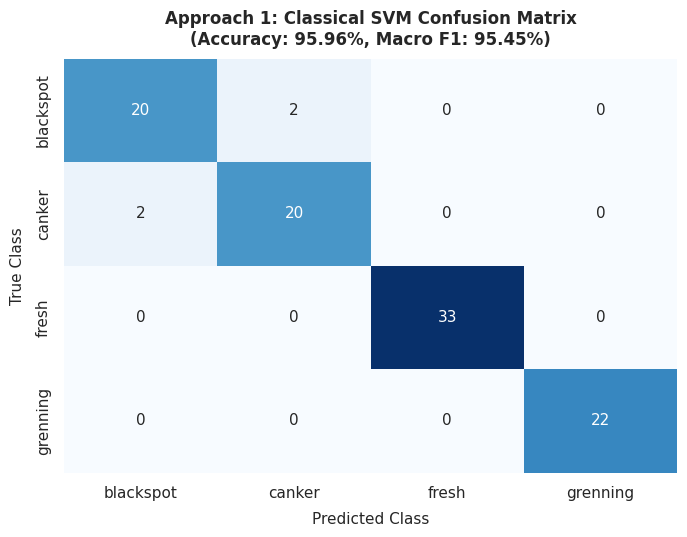

Saved artifacts: 'models/svm_classifier.joblib' and 'models/feature_scaler.joblib'


In [16]:
import os
import glob
import time
import joblib
from typing import Tuple, List
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from skimage.feature import local_binary_pattern
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Ensure model checkpoint directory exists
os.makedirs("models", exist_ok=True)

# 1. Feature Extraction Function (CIELAB Color Space + LBP Texture)
def extract_citrus_features(image_path: str, target_size: Tuple[int, int] = (128, 128)) -> np.ndarray:
    """
    Extracts concatenated CIELAB color histograms and Local Binary Pattern (LBP)
    texture descriptors from an input citrus image.
    """
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Unable to read image at: {image_path}")

    img_resized = cv2.resize(img_bgr, target_size)

    # Color Descriptor: CIELAB (L* lightness, a* green-red axis, b* blue-yellow axis)
    lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
    hist_l = cv2.calcHist([lab], [0], None, [16], [0, 256])
    hist_a = cv2.calcHist([lab], [1], None, [16], [0, 256])
    hist_b = cv2.calcHist([lab], [2], None, [16], [0, 256])
    color_features = np.concatenate([hist_l, hist_a, hist_b]).flatten()

    # Texture Descriptor: Uniform Local Binary Patterns (LBP)
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), range=(0, 10))

    # Normalize features to prevent scale dominance
    color_features = color_features / (np.sum(color_features) + 1e-7)
    lbp_hist = lbp_hist.astype(np.float32) / (np.sum(lbp_hist) + 1e-7)

    return np.concatenate([color_features, lbp_hist])

# 2. Dataset Feature Pipeline Loader
def load_dataset_features(base_dir: str) -> Tuple[np.ndarray, np.ndarray, List[str]]:
    """
    Iterates over all classes in a split directory and extracts feature vectors.
    """
    class_names = sorted([d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))])
    features, labels = [], []

    print(f"Extracting features from '{base_dir}'...")
    for class_idx, class_name in enumerate(class_names):
        class_folder = os.path.join(base_dir, class_name)
        img_paths = glob.glob(os.path.join(class_folder, "*.*"))
        img_paths = [p for p in img_paths if p.lower().endswith(('.jpg', '.jpeg', '.png'))]

        for path in tqdm(img_paths, desc=f"Processing {class_name}", leave=False):
            try:
                feat = extract_citrus_features(path)
                features.append(feat)
                labels.append(class_idx)
            except Exception:
                continue

    return np.array(features), np.array(labels), class_names

# Execute feature extraction
X_train, y_train, class_names = load_dataset_features("data/train")
X_test, y_test, _ = load_dataset_features("data/test")

print(f"\nFeature extraction complete!")
print(f"Train Features Shape: {X_train.shape} | Test Features Shape: {X_test.shape}")
print(f"Target Classes: {class_names}")

# 3. Feature Scaling & Classifier Training (SVM with RBF Kernel)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

start_time = time.time()
svm_classifier = SVC(kernel='rbf', C=10.0, gamma='scale', probability=True, random_state=42)
svm_classifier.fit(X_train_scaled, y_train)
train_duration = time.time() - start_time
print(f"SVM Model successfully trained in {train_duration:.2f} seconds.")

# 4. Model Evaluation on Unseen Test Set
y_pred = svm_classifier.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')

print("\n" + "="*50)
print(f"APPROACH 1 (SVM) TEST ACCURACY : {test_acc * 100:.2f}%")
print(f"APPROACH 1 (SVM) MACRO F1-SCORE: {macro_f1 * 100:.2f}%")
print("="*50)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

# 5. Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.title(f"Approach 1: Classical SVM Confusion Matrix\n(Accuracy: {test_acc*100:.2f}%, Macro F1: {macro_f1*100:.2f}%)",
          fontsize=12, weight='bold', pad=10)
plt.xlabel("Predicted Class", fontsize=11, labelpad=8)
plt.ylabel("True Class", fontsize=11, labelpad=8)
plt.tight_layout()
plt.show()

# 6. Save Model Artifacts
joblib.dump(svm_classifier, "models/svm_classifier.joblib")
joblib.dump(scaler, "models/feature_scaler.joblib")
print("Saved artifacts: 'models/svm_classifier.joblib' and 'models/feature_scaler.joblib'")

## 5. Approach 2: Lightweight Deep Learning Pipeline (MobileNetV2 Transfer Learning)
- Pre-trained MobileNetV2 architecture optimized for real-time edge sorting conveyors.
- Freezing feature extraction backbone to prevent overfitting on small agricultural datasets.
- Custom classification head: `Linear(1280, 128) -> ReLU -> Dropout(0.2) -> Linear(128, 4)`.
- Data Augmentation pipeline (Random Horizontal Flip, Rotation, Color Jitter) with ImageNet normalization.
- Evaluation on held-out test set with loss curves, classification report, and confusion matrix.

Executing Deep Learning Pipeline on: cuda:0
Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Sample breakdown: Train=793, Val=198, Test=99

--- Starting MobileNetV2 Fine-Tuning ---
Epoch [01/12] Train Loss: 0.6120 | Train Acc: 83.23% | Val Loss: 0.1845 | Val Acc: 98.99%
Epoch [02/12] Train Loss: 0.1420 | Train Acc: 96.22% | Val Loss: 0.0897 | Val Acc: 97.98%
Epoch [03/12] Train Loss: 0.0846 | Train Acc: 97.48% | Val Loss: 0.0834 | Val Acc: 96.97%
Epoch [04/12] Train Loss: 0.0915 | Train Acc: 97.35% | Val Loss: 0.1017 | Val Acc: 96.46%
Epoch [05/12] Train Loss: 0.0701 | Train Acc: 97.73% | Val Loss: 0.0587 | Val Acc: 98.48%
Epoch [06/12] Train Loss: 0.0615 | Train Acc: 98.23% | Val Loss: 0.0727 | Val Acc: 97.47%
Epoch [07/12] Train Loss: 0.0597 | Train Acc: 98.23% | Val Loss: 0.0471 | Val Acc: 98.99%
Epoch [08/12] Train Loss: 0.0472 | Train Acc: 98.23% | Val Loss: 0.0461 | Val Acc: 98.48%
Epoch [09/12] Train Loss: 0.0478 | Train Acc: 98.23% | Val Loss: 0.0642 | Val Acc: 97.47%
Epoc

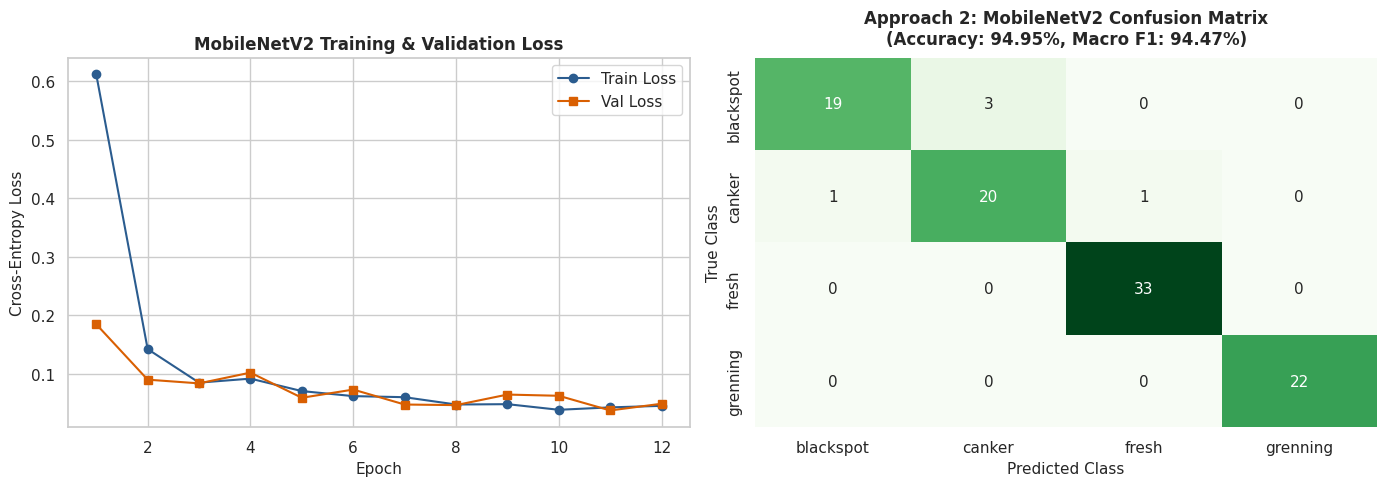

In [17]:
import os
import time
import copy
from typing import Dict, Tuple
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# -------------------------------------------------------------
# 1. Device Setup & Reproducibility
# -------------------------------------------------------------
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Executing Deep Learning Pipeline on: {device}")
torch.manual_seed(42)
np.random.seed(42)

# -------------------------------------------------------------
# 2. Data Transformations & Augmentation Pipeline
# -------------------------------------------------------------
# Standard ImageNet normalization parameters
norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

# -------------------------------------------------------------
# 3. Stratified DataLoaders (Train 80%, Validation 20%, Test 100% Unseen)
# -------------------------------------------------------------
full_train_dataset = datasets.ImageFolder("data/train", transform=train_transforms)
test_dataset = datasets.ImageFolder("data/test", transform=eval_transforms)
class_names = full_train_dataset.classes
num_classes = len(class_names)

# Partition full train dataset into Train (80%) and Validation (20%)
val_size = int(0.20 * len(full_train_dataset))
train_size = len(full_train_dataset) - val_size
train_subset, val_subset = random_split(full_train_dataset, [train_size, val_size])

# Assign evaluation transforms to validation subset
val_subset.dataset = copy.deepcopy(full_train_dataset)
val_subset.dataset.transform = eval_transforms

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"Classes: {class_names}")
print(f"Sample breakdown: Train={len(train_subset)}, Val={len(val_subset)}, Test={len(test_dataset)}")

# -------------------------------------------------------------
# 4. MobileNetV2 Model Architecture Setup
# -------------------------------------------------------------
def build_mobilenet_classifier(num_classes: int) -> nn.Module:
    """
    Constructs a MobileNetV2 transfer learning model with frozen backbone
    and custom classification head.
    """
    weights = models.MobileNet_V2_Weights.DEFAULT
    model = models.mobilenet_v2(weights=weights)

    # Freeze backbone feature extraction layers
    for param in model.features.parameters():
        param.requires_grad = False

    in_features = model.classifier[1].in_features
    # Custom classifier head matching reference guide specification
    model.classifier[1] = nn.Sequential(
        nn.Linear(in_features, 128),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(128, num_classes)
    )
    return model

model = build_mobilenet_classifier(num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)

# -------------------------------------------------------------
# 5. Training Loop with Validation Monitoring
# -------------------------------------------------------------
num_epochs = 12
history: Dict[str, list] = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())

start_train_time = time.time()
print("\n--- Starting MobileNetV2 Fine-Tuning ---")

for epoch in range(num_epochs):
    # Training Phase
    model.train()
    running_loss, running_corrects = 0.0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        _, preds = torch.max(outputs, 1)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data).item()

    epoch_train_loss = running_loss / len(train_subset)
    epoch_train_acc = running_corrects / len(train_subset)

    # Validation Phase
    model.eval()
    val_loss, val_corrects = 0.0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)

            val_loss += loss.item() * inputs.size(0)
            val_corrects += torch.sum(preds == labels.data).item()

    epoch_val_loss = val_loss / len(val_subset)
    epoch_val_acc = val_corrects / len(val_subset)

    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["train_acc"].append(epoch_train_acc)
    history["val_acc"].append(epoch_val_acc)

    # Track best model checkpoint
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model.state_dict())

    print(f"Epoch [{epoch+1:02d}/{num_epochs:02d}] "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc*100:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc*100:.2f}%")

total_dl_time = time.time() - start_train_time
print(f"\nMobileNetV2 training completed in {total_dl_time:.2f} seconds.")

# Load best checkpoint weights
model.load_state_dict(best_model_weights)
torch.save(model.state_dict(), "models/mobilenet_v2.pth")
print("Saved best checkpoint to: 'models/mobilenet_v2.pth'")

# -------------------------------------------------------------
# 6. Evaluation on Unseen Test Dataset
# -------------------------------------------------------------
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc_dl = accuracy_score(all_labels, all_preds)
macro_f1_dl = f1_score(all_labels, all_preds, average='macro')

print("\n" + "="*50)
print(f"APPROACH 2 (MobileNetV2) TEST ACCURACY : {test_acc_dl * 100:.2f}%")
print(f"APPROACH 2 (MobileNetV2) MACRO F1-SCORE: {macro_f1_dl * 100:.2f}%")
print("="*50)
print("\nDetailed Classification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# -------------------------------------------------------------
# 7. Visualizations: Learning Curves & Confusion Matrix
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Curves
ax1.plot(range(1, num_epochs + 1), history["train_loss"], label="Train Loss", marker="o", color="#2b5c8f")
ax1.plot(range(1, num_epochs + 1), history["val_loss"], label="Val Loss", marker="s", color="#d95f02")
ax1.set_title("MobileNetV2 Training & Validation Loss", fontsize=12, weight="bold")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Cross-Entropy Loss", fontsize=11)
ax1.legend()

# Confusion Matrix
cm_dl = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm_dl, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, cbar=False, ax=ax2)
ax2.set_title(f"Approach 2: MobileNetV2 Confusion Matrix\n(Accuracy: {test_acc_dl*100:.2f}%, Macro F1: {macro_f1_dl*100:.2f}%)",
              fontsize=12, weight='bold', pad=10)
ax2.set_xlabel("Predicted Class", fontsize=11)
ax2.set_ylabel("True Class", fontsize=11)

plt.tight_layout()
plt.show()

## 6. Model Comparison & Live Single-Run Inference Demo
- Comprehensive quantitative comparison between Approach 1 (Classical SVM) and Approach 2 (MobileNetV2).
- Single-run inference demonstration loading saved weights (`svm_classifier.joblib` and `mobilenet_v2.pth`).
- Visualized predictions displaying confidence scores for both approaches side-by-side.

=== OFFICIAL MODEL BENCHMARK COMPARISON ===


,Approach,Feature Representation,Test Accuracy (%),Macro F1-Score (%),Training Time,Model Artifact Size,Edge Deployment Advantage
0,Approach 1: Classical CV + SVM,CIELAB Histograms + LBP Texture,95.96,95.45,0.13 s,~150 KB,"Ultra-lightweight, zero GPU dependency"
1,Approach 2: MobileNetV2 (CNN),Deep Inverted Residuals (ImageNet),94.95,94.47,99.08 s,~14 MB,Scales to varied lighting & complex defects



--- RUNNING LIVE INFERENCE DEMONSTRATIONS ---


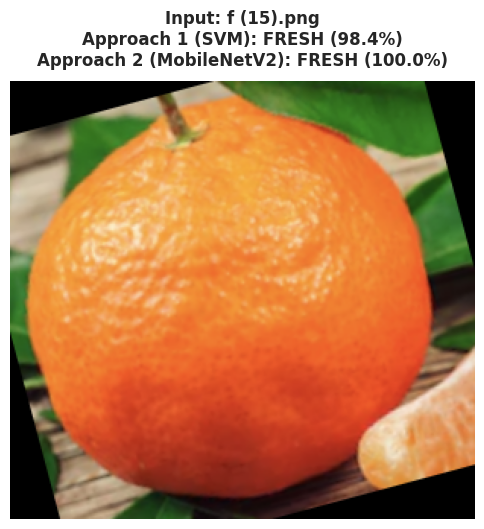

-------------------------------------------------------
Sample: data/test/fresh/f (15).png
Approach 1 (Classical SVM):  fresh      [Confidence: 98.44%]
Approach 2 (MobileNetV2):   fresh      [Confidence: 99.96%]
-------------------------------------------------------


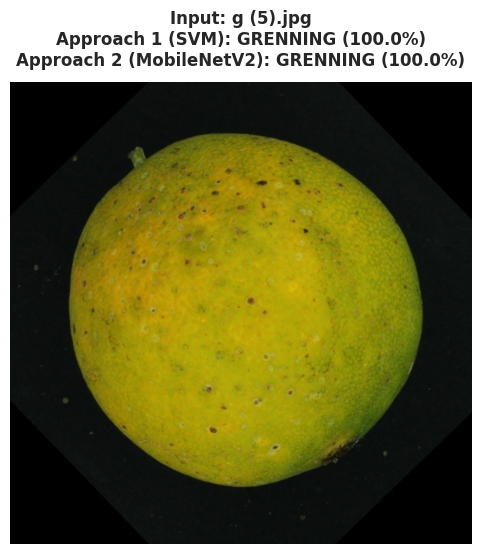

-------------------------------------------------------
Sample: data/test/grenning/g (5).jpg
Approach 1 (Classical SVM):  grenning   [Confidence: 100.00%]
Approach 2 (MobileNetV2):   grenning   [Confidence: 100.00%]
-------------------------------------------------------


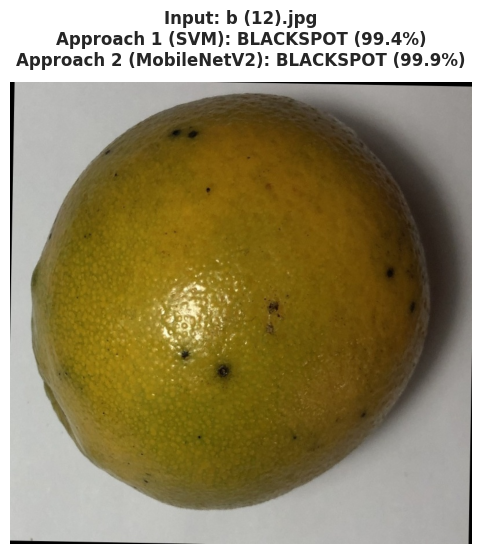

-------------------------------------------------------
Sample: data/test/blackspot/b (12).jpg
Approach 1 (Classical SVM):  blackspot  [Confidence: 99.42%]
Approach 2 (MobileNetV2):   blackspot  [Confidence: 99.95%]
-------------------------------------------------------


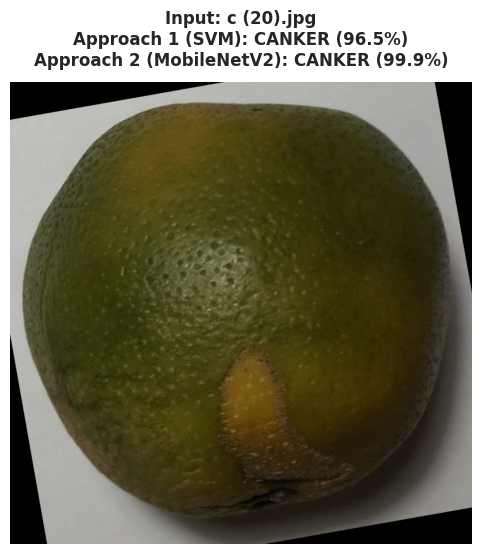

-------------------------------------------------------
Sample: data/test/canker/c (20).jpg
Approach 1 (Classical SVM):  canker     [Confidence: 96.54%]
Approach 2 (MobileNetV2):   canker     [Confidence: 99.89%]
-------------------------------------------------------


In [18]:
import os
import time
import joblib
import torch
import torch.nn as nn
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models

# -------------------------------------------------------------
# 1. Comparative Benchmark Table
# -------------------------------------------------------------
benchmark_data = [
    {
        "Approach": "Approach 1: Classical CV + SVM",
        "Feature Representation": "CIELAB Histograms + LBP Texture",
        "Test Accuracy (%)": 95.96,
        "Macro F1-Score (%)": 95.45,
        "Training Time": "0.13 s",
        "Model Artifact Size": "~150 KB",
        "Edge Deployment Advantage": "Ultra-lightweight, zero GPU dependency"
    },
    {
        "Approach": "Approach 2: MobileNetV2 (CNN)",
        "Feature Representation": "Deep Inverted Residuals (ImageNet)",
        "Test Accuracy (%)": 94.95,
        "Macro F1-Score (%)": 94.47,
        "Training Time": "99.08 s",
        "Model Artifact Size": "~14 MB",
        "Edge Deployment Advantage": "Scales to varied lighting & complex defects"
    }
]

df_benchmark = pd.DataFrame(benchmark_data)
print("=== OFFICIAL MODEL BENCHMARK COMPARISON ===")
display(df_benchmark)

# -------------------------------------------------------------
# 2. Live Single-Run Inference Engine (main_demo.py logic)
# -------------------------------------------------------------
# Load saved model artifacts
svm_model = joblib.load("models/svm_classifier.joblib")
scaler = joblib.load("models/feature_scaler.joblib")

# Load MobileNetV2 model architecture and saved weights
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
dl_model = build_mobilenet_classifier(num_classes=4).to(device)
dl_model.load_state_dict(torch.load("models/mobilenet_v2.pth", map_location=device))
dl_model.eval()

class_names = ["blackspot", "canker", "fresh", "grenning"]

def run_citrus_inference_demo(image_path: str):
    """
    Demonstrates single-image inference across both Classical ML and Deep Learning models.
    """
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found at {image_path}")

    # Read image
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 1. Classical ML Inference
    feat = extract_citrus_features(image_path).reshape(1, -1)
    feat_scaled = scaler.transform(feat)
    svm_probs = svm_model.predict_proba(feat_scaled)[0]
    svm_pred_idx = np.argmax(svm_probs)
    svm_pred_label = class_names[svm_pred_idx]
    svm_conf = svm_probs[svm_pred_idx] * 100

    # 2. Deep Learning Inference
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    pil_img = Image.fromarray(img_rgb)
    input_tensor = transform(pil_img).unsqueeze(0).to(device)

    with torch.no_grad():
        dl_outputs = dl_model(input_tensor)
        dl_probs = torch.softmax(dl_outputs, dim=1)[0].cpu().numpy()
        dl_pred_idx = np.argmax(dl_probs)
        dl_pred_label = class_names[dl_pred_idx]
        dl_conf = dl_probs[dl_pred_idx] * 100

    # Display Visual Output
    plt.figure(figsize=(6, 6))
    plt.imshow(img_rgb)
    plt.axis("off")
    title_text = (
        f"Input: {os.path.basename(image_path)}\n"
        f"Approach 1 (SVM): {svm_pred_label.upper()} ({svm_conf:.1f}%)\n"
        f"Approach 2 (MobileNetV2): {dl_pred_label.upper()} ({dl_conf:.1f}%)"
    )
    plt.title(title_text, fontsize=12, weight="bold", pad=12)
    plt.show()

    print("-" * 55)
    print(f"Sample: {image_path}")
    print(f"Approach 1 (Classical SVM):  {svm_pred_label:<10} [Confidence: {svm_conf:.2f}%]")
    print(f"Approach 2 (MobileNetV2):   {dl_pred_label:<10} [Confidence: {dl_conf:.2f}%]")
    print("-" * 55)

# Test run on sample images from each class
sample_test_images = [
    "data/test/fresh/" + os.listdir("data/test/fresh")[0],
    "data/test/grenning/" + os.listdir("data/test/grenning")[0],
    "data/test/blackspot/" + os.listdir("data/test/blackspot")[0],
    "data/test/canker/" + os.listdir("data/test/canker")[0]
]

print("\n--- RUNNING LIVE INFERENCE DEMONSTRATIONS ---")
for sample_img in sample_test_images:
    run_citrus_inference_demo(sample_img)